# 02. 회귀 예측 분포 재기 — CRPS, 구간, PIT

TabPFN 회귀는 숫자 하나가 아니라 분포를 냅니다(bar distribution, [01_pfn/03](../01_pfn/03_pfn_implementation_details.ipynb) 6절). RMSE는 그 분포의 평균만 봅니다. 평균이 같아도 분포가 너무 좁으면 "확실하다"고 말하고 틀리고, 너무 넓으면 쓸모가 없습니다. 이 노트북은 분포 자체를 채점하는 지표를 작은 예로 따라갑니다. 이 저장소의 구현은 `minipfn/benchmarks/uncertainty.py`입니다(issue #45).

다루는 흐름:

1. 평균은 같고 분포만 다른 예측 넷
2. CRPS — 분포 전체를 한 숫자로
3. 구간 — coverage, 폭, interval score, 조건부 coverage
4. PIT — 분포 모양이 맞는지
5. TabPFN v2 회귀를 같은 지표로
6. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/topics_evaluation/` 아래에 있으므로 저장소 루트는 두 단계 위입니다. 5절은 Hub에서 v2 회귀 가중치(`aiden-jeon/minipfn-tabpfn-v2-regressor`)를 받습니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

from minipfn import TabPFNv2Regressor, set_seed
from minipfn.benchmarks import uncertainty as unc

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.
# 꼬리 구간 확률이 0이면 quantile의 np.where가 쓰지 않는 갈래에서 0으로 나눠 경고를 낸다
# (값은 그대로다)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1. 평균은 같고 분포만 다른 예측 넷

집에서 회사까지의 거리(km)로 출근 시간(분)을 예측합니다. 평균은 $3 \times$ 거리 $+ 10$분이고, 멀수록 길이 막히는 날과 안 막히는 날의 차이가 커서 퍼짐(표준편차)이 $0.5 + 0.4 \times$ 거리분으로 늘어납니다. 2km면 ±1.3분, 20km면 ±8.5분입니다.

이 데이터를 아는 사람이 예측 넷을 냅니다. 넷 모두 평균은 정답 평균 그대로이고, 표준편차만 다릅니다.

- **맞음**: 정답 표준편차
- **너무 좁음**: 정답의 절반
- **너무 넓음**: 정답의 두 배
- **폭 고정**: 거리와 상관없이 모든 행에 같은 표준편차(정답 분산의 평균의 제곱근)

In [3]:
rng = np.random.default_rng(0)
n_test = 1000
distance = rng.uniform(1, 20, n_test)  # km
true_mean = 3 * distance + 10  # 분
true_sd = 0.5 + 0.4 * distance
minutes = true_mean + true_sd * rng.normal(size=n_test)  # 실제 출근 시간

sds = {
    "right": true_sd,
    "too narrow": 0.5 * true_sd,
    "too wide": 2.0 * true_sd,
    "fixed width": np.full(n_test, np.sqrt(np.mean(true_sd**2))),
}
preview = pd.DataFrame({"거리 km": distance, "실제 분": minutes, "평균": true_mean})
for name, sd in sds.items():
    preview[f"sd ({name})"] = sd
display(preview.head(5).round(2))

,거리 km,실제 분,평균,sd (right),sd (too narrow),sd (too wide),sd (fixed width)
0,13.10,49.79,49.31,5.74,2.87,11.48,5.29
1,6.13,31.02,28.38,2.95,1.48,5.90,5.29
2,1.78,18.01,15.34,1.21,0.61,2.42,5.29
3,1.31,14.69,13.94,1.03,0.51,2.05,5.29
4,16.45,49.41,59.36,7.08,3.54,14.16,5.29


지표 함수는 TabPFN이 내는 모양, 곧 경계 `borders`(구간 수 + 1개)와 구간마다의 확률 `probs`(행 × 구간 수)를 받습니다. 정규분포를 그 모양으로 바꿉니다. 구간 하나의 확률은 그 구간 양 끝에서의 CDF 차이입니다.

In [4]:
borders = np.linspace(-40, 160, 2001)  # 0.1분 간격 구간 2,000개


def to_bars(mean, sd):
    cdf = stats.norm.cdf((borders[None, :] - mean[:, None]) / sd[:, None])
    return np.diff(cdf, axis=1)  # 구간마다의 확률 (n, 2000)


histograms = {name: unc.bar_histogram(to_bars(true_mean, sd), borders) for name, sd in sds.items()}
rmse = np.sqrt(np.mean((true_mean - minutes) ** 2))
print(f"RMSE (넷 모두 같은 평균): {rmse:.2f}분")

RMSE (넷 모두 같은 평균): 5.33분


RMSE는 넷 모두 같습니다. 이제 분포를 보는 지표로 넷을 가립니다.

## 2. CRPS — 분포 전체를 한 숫자로

CRPS(continuous ranked probability score)는 예측 CDF $F$와 정답 $y$에서 0에서 1로 뛰는 계단 함수의 차이를 제곱해 적분합니다.

$$\mathrm{CRPS}(F, y) = \int \left(F(t) - \mathbf{1}\{t \ge y\}\right)^2 dt$$

예측이 $y$ 한 점에 몰려 있으면 0이고, 분포가 넓거나 엉뚱한 곳에 있으면 커집니다. 단위는 $y$와 같은 분이고, 분포가 한 점이면 절대오차와 같습니다. 행 하나(첫 행)에서 세 예측의 CDF와 계단을 그려 봅니다. 두 곡선이 벌어진 곳(색칠한 부분)이 넓을수록 CRPS가 큽니다.

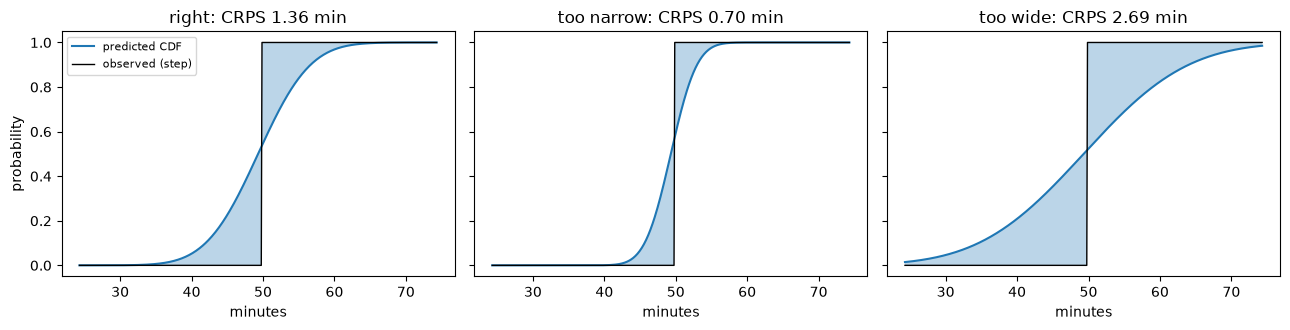

첫 행: 거리 13.1km, 평균 49.3분, 실제 49.8분


In [5]:
row = 0
y_row = minutes[row]
t = np.linspace(true_mean[row] - 25, true_mean[row] + 25, 500)
step = (t >= y_row).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, name in zip(axes, ["right", "too narrow", "too wide"], strict=True):
    cdf = stats.norm.cdf((t - true_mean[row]) / sds[name][row])
    ax.plot(t, cdf, label="predicted CDF")
    ax.plot(t, step, color="k", lw=1, label="observed (step)")
    ax.fill_between(t, cdf, step, alpha=0.3)
    row_crps = unc.crps(histograms[name], minutes)[row]
    ax.set_title(f"{name}: CRPS {row_crps:.2f} min")
    ax.set_xlabel("minutes")
axes[0].set_ylabel("probability")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"첫 행: 거리 {distance[row]:.1f}km, 평균 {true_mean[row]:.1f}분, 실제 {y_row:.1f}분")

CRPS는 행마다 이렇게 계산해 평균합니다. 네 예측의 평균 CRPS를 봅니다.

In [6]:
crps_table = pd.Series({name: unc.crps(h, minutes).mean() for name, h in histograms.items()})
display(crps_table.round(3).to_frame("CRPS (분, 작을수록 좋음)"))

,"CRPS (분, 작을수록 좋음)"
right,2.781
too narrow,3.023
too wide,3.200
fixed width,2.921


평균으로는 맞는 분포가 가장 작습니다(2.781). 그런데 첫 행에서는 너무 좁은 예측이 이겼습니다(0.70). 실제 값이 평균에 아주 가까운 행이라 좁게 몰아 말한 것이 들어맞았기 때문입니다. 실제 값이 평균에서 먼 행에서는 좁은 예측이 크게 집니다. CRPS는 proper scoring rule이라, 실제 분포를 그대로 말할 때 평균 점수가 가장 좋아집니다. 그래서 행 하나가 아니라 평균으로 판정합니다. 폭 고정(2.921)은 맞는 분포와 너무 좁은 예측 사이입니다.

## 3. 구간 — coverage, 폭, interval score, 조건부 coverage

분포에서 가운데 90% 구간 $[Q(0.05), Q(0.95)]$을 꺼내면 "출근에 32~45분 걸린다" 같은 말이 됩니다. 이 구간을 세 가지로 잽니다(`interval_scores`).

- **coverage**: 실제 값이 구간 안에 든 비율. 90% 구간이면 0.9여야 합니다.
- **폭**: 구간의 평균 길이. coverage가 맞는다면 좁을수록 좋습니다.
- **interval score**: 폭 + $\frac{2}{\alpha}$ × 구간 밖으로 벗어난 거리($\alpha = 0.1$). 너무 좁아 자주 벗어나는 구간과 너무 넓은 구간을 한 숫자로 함께 벌줍니다(Gneiting & Raftery 2007).

In [7]:
interval_rows = {}
for name, h in histograms.items():
    scores = unc.interval_scores(h, minutes, levels=(0.9,))
    interval_rows[name] = {
        "coverage 90": scores["coverage_90"],
        "폭 90 (분)": scores["width_90"],
        "interval score 90": scores["interval_score_90"],
        "폭 5분위별 coverage 최솟값": scores["coverage_min_by_width_90"],
    }
display(pd.DataFrame(interval_rows).T.round(3))

,coverage 90,폭 90 (분),interval score 90,폭 5분위별 coverage 최솟값
right,0.894,15.885,20.116,0.855
too narrow,0.574,7.944,31.228,0.535
too wide,1.000,31.769,31.769,1.000
fixed width,0.894,17.406,23.736,0.875


맞는 분포는 coverage가 0.894로 90%에 가깝고 interval score가 가장 작습니다(20.1). 너무 좁은 예측은 폭이 절반이지만 실제 값이 자주 구간 밖으로 나가(coverage 0.574) 벌점이 커지고, 너무 넓은 예측은 늘 담지만(1.000) 폭이 두 배라 interval score가 비슷하게 나쁩니다. 폭 고정은 coverage가 맞는 분포와 같은 0.894라 전체로는 90%를 맞힌 셈입니다. 그런데 거리별로 나눠 보면 다릅니다.

In [8]:
distance_bin = pd.qcut(distance, 5, labels=["1-5 km", "5-9 km", "9-12 km", "12-16 km", "16-20 km"])
by_distance = {}
for name, h in histograms.items():
    low, high = unc.quantile(h, np.array([0.05, 0.95])).T
    covered = (minutes >= low) & (minutes <= high)
    by_distance[name] = pd.Series(covered).groupby(distance_bin, observed=True).mean()
by_distance = pd.DataFrame(by_distance)
by_distance.index.name = "거리 5분위"
display(by_distance.round(2))

,right,too narrow,too wide,fixed width
거리 5분위,,,,
1-5 km,0.92,0.59,1.0,1.00
5-9 km,0.88,0.54,1.0,0.98
9-12 km,0.86,0.54,1.0,0.89
12-16 km,0.90,0.55,1.0,0.82
16-20 km,0.92,0.66,1.0,0.78


폭 고정 예측은 가까운 출근(1~5km)에서는 모두 담고(1.00), 먼 출근(16~20km)에서는 0.78만 담습니다. 쉬운 행에서 남는 coverage로 어려운 행에서 모자란 coverage를 메워 전체가 0.894가 된 것입니다. 맞는 분포는 다섯 묶음 모두 0.86~0.92입니다. 이렇게 행의 성질마다 따로 맞는지를 조건부 coverage라고 합니다.

실제 benchmark에서는 "거리" 같은 열을 미리 알 수 없어서, 저장소는 예측한 구간 폭으로 행을 5분위로 나눠 그 가운데 가장 낮은 coverage를 냅니다(3절 표의 마지막 열). 넓게 예측한 행과 좁게 예측한 행을 똑같이 맞히는지, 곧 모델이 "이 행은 어렵다"고 말할 때 그 말이 맞는지를 봅니다. 그래서 폭이 모두 같은 예측은 이 지표로 가리지 못합니다. 폭 고정 예측의 폭은 구간 경계의 격자 때문에 아주 조금씩만 달라서 5분위가 사실상 무작위로 나뉘고, 그 값(0.875)도 노이즈입니다.

## 4. PIT — 분포 모양이 맞는지

PIT(probability integral transform)는 행마다 실제 값이 예측 분포에서 몇 번째 분위에 있는지, 곧 $F(y)$입니다. 분포가 맞으면 $F(y)$는 0~1에 고르게 퍼집니다. 너무 좁으면 실제 값이 양 끝(0이나 1 근처)에 자주 떨어져 U자가 되고, 너무 넓으면 가운데(0.5 근처)에 몰립니다. 고른 분포와의 거리를 KS 통계량(`pit_ks`)으로 냅니다.

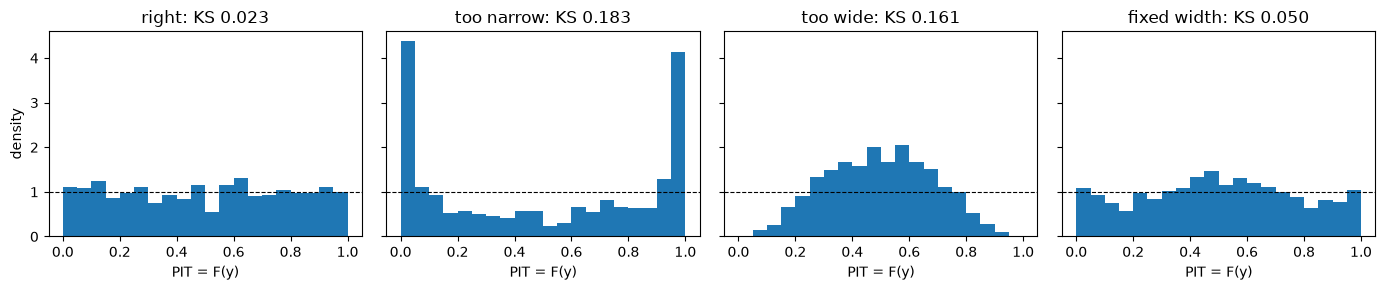

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for ax, (name, h) in zip(axes, histograms.items(), strict=True):
    values = unc.pit(h, minutes)
    ax.hist(values, bins=20, range=(0, 1), density=True)
    ax.axhline(1.0, color="k", lw=0.8, ls="--")
    ax.set_title(f"{name}: KS {unc.pit_ks(values):.3f}")
    ax.set_xlabel("PIT = F(y)")
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

맞는 분포는 막대가 점선(밀도 1) 근처에 고르게 퍼지고 KS가 0.023입니다. 너무 좁은 예측은 실제 값이 분포의 양 끝에 자주 떨어져 U자가 되고, 너무 넓은 예측은 가운데에 몰려 산 모양이 됩니다. 폭 고정은 KS 0.050으로 그 사이입니다. 가까운 출근에서는 넓어서 가운데로, 먼 출근에서는 좁아서 양 끝으로 가는 효과가 섞여 서로 일부 지워집니다.

## 5. TabPFN v2 회귀를 같은 지표로

같은 규칙으로 학습 행 300개를 따로 만들어 TabPFN v2 회귀에 넣고, 위의 test 행 1,000개에서 분포를 받습니다. `predict_distribution`이 (구간마다의 log 확률, 경계)를 주므로 `np.exp`해서 지표 함수에 그대로 넣습니다. `regression_metrics`가 1~4절의 지표를 한 번에 냅니다.

In [10]:
train_distance = rng.uniform(1, 20, 300)
train_minutes = 3 * train_distance + 10 + (0.5 + 0.4 * train_distance) * rng.normal(size=300)

regressor = TabPFNv2Regressor().fit(train_distance[:, None], train_minutes)
log_probs, tabpfn_borders = regressor.predict_distribution(distance[:, None])
tabpfn_probs = np.exp(log_probs.numpy())
print("TabPFN 분포:", tabpfn_probs.shape, "경계", tabpfn_borders.shape)

compare = {}
for name, h in {**histograms}.items():
    compare[name] = unc.regression_metrics(h.probs, h.borders, minutes)
compare["TabPFN v2"] = unc.regression_metrics(tabpfn_probs, tabpfn_borders.numpy(), minutes)
compare["TabPFN v2"]["rmse"] = np.sqrt(
    np.mean((regressor.predict(distance[:, None]) - minutes) ** 2)
)
for name in sds:
    compare[name]["rmse"] = rmse
columns = ["rmse", "crps", "coverage_90", "width_90", "interval_score_90", "pit_ks"]
display(pd.DataFrame(compare).T[columns].round(3))

TabPFN 분포: (1000, 5000) 경계 torch.Size([5001])


,rmse,crps,coverage_90,width_90,interval_score_90,pit_ks
right,5.330,2.781,0.894,15.885,20.116,0.023
too narrow,5.330,3.023,0.574,7.944,31.228,0.183
too wide,5.330,3.200,1.000,31.769,31.769,0.161
fixed width,5.330,2.921,0.894,17.406,23.736,0.050
TabPFN v2,5.469,2.877,0.864,14.798,21.067,0.061


학습 행 300개만 본 TabPFN v2가 정답 분포를 아는 예측에 꽤 가깝습니다. CRPS 2.877은 맞는 분포(2.781)와 폭 고정(2.921) 사이이고, 90% 구간은 coverage 0.864로 조금 좁으며(폭 14.8분), PIT KS는 0.061입니다. 평균도 정답이 아니라 학습 행에서 배운 것이라 RMSE가 조금 큽니다(5.47). 이 저장소의 AMLB 평가는 회귀 fold마다 이 지표를 남기고, 데이터셋끼리 평균할 때는 학습 target의 표준편차로 나눈 값(`_scaled`)을 씁니다.

## 6. 정리

| 지표 | 무엇을 보나 | 맞는 분포에서 | `uncertainty.py` |
|---|---|---|---|
| CRPS | 분포 전체가 실제 값에 얼마나 가까운가 (단위는 y) | 가장 작다 | `crps` |
| coverage | 구간이 실제 값을 담는 비율 | 수준과 같다 (90% → 0.9) | `interval_scores` |
| 폭 | 구간의 길이 | coverage가 맞는 것 가운데 가장 좁다 | `interval_scores` |
| interval score | 폭 + 벗어난 거리의 벌점 | 가장 작다 | `interval_scores` |
| 폭 분위별 coverage 최솟값 | 넓은 구간과 좁은 구간을 똑같이 맞히나 | 수준에 가깝다 | `min_coverage_by_width` |
| PIT KS | $F(y)$가 고르게 퍼지나 | 0에 가깝다 | `pit`, `pit_ks` |

- 평균이 같으면 RMSE로는 분포를 가릴 수 없습니다(1절).
- marginal coverage가 맞아도 쉬운 행과 어려운 행에서 따로 보면 틀릴 수 있습니다(3절의 폭 고정).
- 평가 명령: `scripts/tabpfn_v2/eval.py --uncertainty`(AMLB 회귀 fold마다 이 지표를 남깁니다).